<a href="https://colab.research.google.com/github/Kaveesha-Madhushan17/Early-Detection-of-Oral-cancer/blob/main/01_pilot_tiling_macenko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Pilot image pipeline on our slides
**E21 FYP Group 18** · tissue detection → 512×512 tiles → Macenko stain normalisation

What this notebook makes for the slide:
1. a slide thumbnail with the tissue mask
2. a grid of sample tiles
3. tiles before and after Macenko normalisation
4. a table: number of tissue tiles per slide and per group

**Before you run:** in Google Drive, open the shared folder *Scanned slides_with Single images* → right click → **Organize → Add shortcut → My Drive**.

In [ ]:
# 1. Install and mount Drive
!apt-get -qq install -y openslide-tools > /dev/null
!pip -q install openslide-python scikit-image
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Settings: change ROOT if your shortcut has another name
ROOT = '/content/drive/MyDrive/Scanned slides_with Single images'
OUT  = '/content/drive/MyDrive/FYP_G18_pilot/01_tiles'
TILE = 512          # tile size in pixels
TISSUE_MIN = 0.5    # keep a tile if at least 50% is tissue
import os, glob
os.makedirs(OUT, exist_ok=True)
EXT = ('.svs','.ndpi','.mrxs','.tif','.tiff','.jpg','.jpeg','.png')
files = [p for p in glob.glob(ROOT+'/**/*', recursive=True) if p.lower().endswith(EXT)]
print(len(files), 'image files found')
for g in sorted(os.listdir(ROOT)):
    n = len([f for f in files if f'/{g}/' in f])
    print(f'  {g:20s} {n}')
print('\nExamples:'); [print('  ', f.replace(ROOT,'')) for f in files[:10]]

7811 image files found
  Healthy              1458
  OLK_Dysplasia        1705
  OLP                  1480
  OSCC                 2371
  OSF                  797

Examples:
   /Healthy/2026-10-28-1409-19_878/Tile000001.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000002.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000003.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000004.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000005.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000006.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000007.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000008.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000009.jpg
   /Healthy/2026-10-28-1409-19_878/Tile000010.jpg


[None, None, None, None, None, None, None, None, None, None]

**Check the output above.** You should see the five groups (Healthy, OLK_Dysplasia, OLP, OSCC, OSF). If you see 0 files, fix `ROOT`. Note which files are whole slide images (.svs/.ndpi/.tif) and which are single images (.jpg/.png).

In [ ]:
# 3. Helper functions: open an image, tissue mask, Macenko
import numpy as np, matplotlib.pyplot as plt
from PIL import Image
from skimage.filters import threshold_otsu
from skimage.color import rgb2hsv
Image.MAX_IMAGE_PIXELS = None

def open_image(path, max_side=None):
    """Returns (full_reader, thumbnail RGB array, mpp)."""
    if path.lower().endswith(('.svs','.ndpi','.mrxs','.tif','.tiff')):
        try:
            import openslide
            s = openslide.OpenSlide(path)
            mpp = s.properties.get('openslide.mpp-x')
            th = np.array(s.get_thumbnail((2048,2048)).convert('RGB'))
            return s, th, mpp
        except Exception:
            pass
    im = Image.open(path).convert('RGB')
    th = im.copy(); th.thumbnail((2048,2048))
    return im, np.array(th), None

def tissue_mask(rgb):
    sat = rgb2hsv(rgb)[...,1]
    t = threshold_otsu(sat)
    return sat > max(t, 0.05)

def read_tile(reader, x, y, size):
    if hasattr(reader, 'read_region'):
        return np.array(reader.read_region((x,y), 0, (size,size)).convert('RGB'))
    return np.array(reader.crop((x,y,x+size,y+size)))

def full_size(reader):
    return reader.dimensions if hasattr(reader,'dimensions') else reader.size

class Macenko:
    """Macenko stain normalisation (Macenko et al., ISBI 2009)."""
    def __init__(self, Io=240, alpha=1, beta=0.15):
        self.Io, self.alpha, self.beta = Io, alpha, beta
    def _stain(self, img):
        od = -np.log((img.reshape(-1,3).astype(float)+1)/self.Io)
        od_hat = od[~np.any(od < self.beta, axis=1)]
        _, V = np.linalg.eigh(np.cov(od_hat.T))
        V = V[:, [1,2]]
        if V[0,0] < 0: V[:,0] *= -1
        if V[0,1] < 0: V[:,1] *= -1
        th = od_hat @ V
        phi = np.arctan2(th[:,1], th[:,0])
        mn, mx = np.percentile(phi, self.alpha), np.percentile(phi, 100-self.alpha)
        v1 = V @ np.array([np.cos(mn), np.sin(mn)]); v2 = V @ np.array([np.cos(mx), np.sin(mx)])
        HE = np.array([v1, v2]).T if v1[0] > v2[0] else np.array([v2, v1]).T
        C = np.linalg.lstsq(HE, od.T, rcond=None)[0]
        return HE, C, np.percentile(C, 99, axis=1)
    def fit(self, target):
        self.HE, _, self.maxC = self._stain(target); return self
    def transform(self, img):
        h, w, _ = img.shape
        _, C, maxC = self._stain(img)
        C = C * (self.maxC / maxC)[:, None]
        out = self.Io * np.exp(-self.HE @ C)
        return np.clip(out.T.reshape(h, w, 3), 0, 255).astype(np.uint8)
print('ready')

ready


In [ ]:
import pandas as pd, numpy as np
from collections import defaultdict
slides = defaultdict(list)
for f in files:
    parts = f.replace(ROOT,'').strip('/').split('/')
    if len(parts) >= 3:
        slides[(parts[0], parts[1])].append(f)
rows = []
for (g, s), fs in slides.items():
    tiles = [x for x in fs if os.path.basename(x).lower().startswith('tile')]
    other = [x for x in fs if x not in tiles]
    rows.append(dict(group=g, slide=s, n_tiles=len(tiles), single_images=len(other)))
df = pd.DataFrame(rows); df.to_csv(OUT+'/tiles_per_slide.csv', index=False)
print(df.groupby('group').agg(slides=('slide','count'), mean_tiles=('n_tiles','mean'),
                             min_tiles=('n_tiles','min'), max_tiles=('n_tiles','max')).round(0))
print('\nSingle (non tile) images per slide:', df.single_images.unique())
im = Image.open(slides[list(slides)[0]][0]); print('Tile size:', im.size)

               slides  mean_tiles  min_tiles  max_tiles
group                                                  
Healthy            11       131.0         40        304
OLK_Dysplasia      10       168.0         72        528
OLP                17        85.0         30        170
OSCC                9       261.0         72        504
OSF                 6       131.0         56        341

Single (non tile) images per slide: [2]
Tile size: (1568, 1568)


OSCC slide 2026-10-28-1401-15_785: 288 tiles, 37 with ≥50% tissue


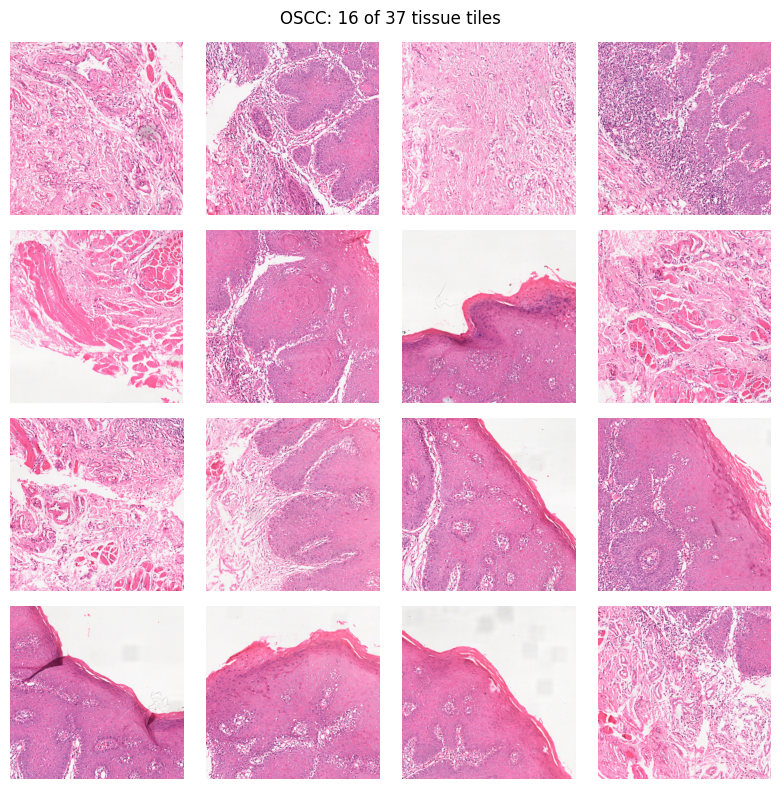

In [ ]:
g = 'OSCC'
key = next(k for k in slides if k[0]==g)
tiles = sorted(x for x in slides[key] if os.path.basename(x).lower().startswith('tile'))
def tissue_frac(p):
    a = np.array(Image.open(p).convert('RGB').resize((128,128)))
    return tissue_mask(a).mean()
fr = [tissue_frac(p) for p in tiles]
keep = [p for p, f in zip(tiles, fr) if f >= TISSUE_MIN]
print(f'{g} slide {key[1]}: {len(tiles)} tiles, {len(keep)} with ≥50% tissue')
import random; random.seed(0); pick = random.sample(keep, min(16, len(keep)))
fig, ax = plt.subplots(4, 4, figsize=(8,8))
for a, p in zip(ax.ravel(), pick): a.imshow(Image.open(p)); a.axis('off')
plt.suptitle(f'{g}: 16 of {len(keep)} tissue tiles'); plt.tight_layout()
plt.savefig(OUT+'/fig2_tile_grid.png', dpi=200); plt.show()

In [ ]:
k = list(slides)[0]
print([os.path.basename(x) for x in slides[k] if not os.path.basename(x).lower().startswith('tile')])

['2026-10-28-1409-19.svs', 'ViewExport.jpg']


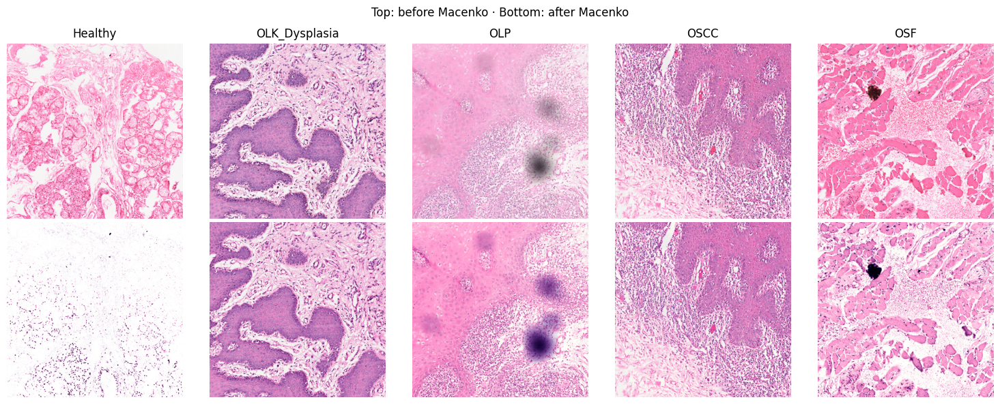

In [ ]:
groups = sorted({k[0] for k in slides})
from skimage.color import rgb2hed
def h_score(p):
    a = np.array(Image.open(p).convert('RGB').resize((128,128)))
    tissue = rgb2hsv(a)[...,1] > 0.15
    nuclei = rgb2hed(a)[...,0] > 0.03           # hematoxylin (purple nuclei)
    return tissue.mean() * nuclei.mean()        # needs both tissue and nuclei

def mid_tissue_tile(g):
    k = next(k for k in slides if k[0]==g)
    ts = sorted(x for x in slides[k] if os.path.basename(x).lower().startswith('tile'))
    cand = ts[::max(1, len(ts)//60)]            # check about 60 tiles
    best = max(cand, key=h_score)
    return np.array(Image.open(best).convert('RGB'))
samples = {g: mid_tissue_tile(g) for g in groups}
norm = Macenko().fit(samples['OSCC'])
fig, ax = plt.subplots(2, len(groups), figsize=(3*len(groups), 6))
for i, g in enumerate(groups):
    t = samples[g]
    try: n = norm.transform(t)
    except Exception: n = t
    ax[0,i].imshow(t); ax[0,i].set_title(g); ax[0,i].axis('off')
    ax[1,i].imshow(n); ax[1,i].axis('off')
plt.suptitle('Top: before Macenko · Bottom: after Macenko'); plt.tight_layout()
plt.savefig(OUT+'/fig3_macenko.png', dpi=200); plt.show()

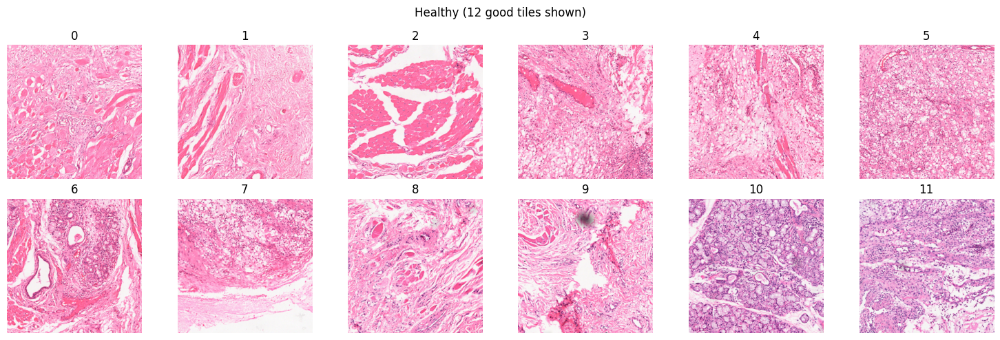

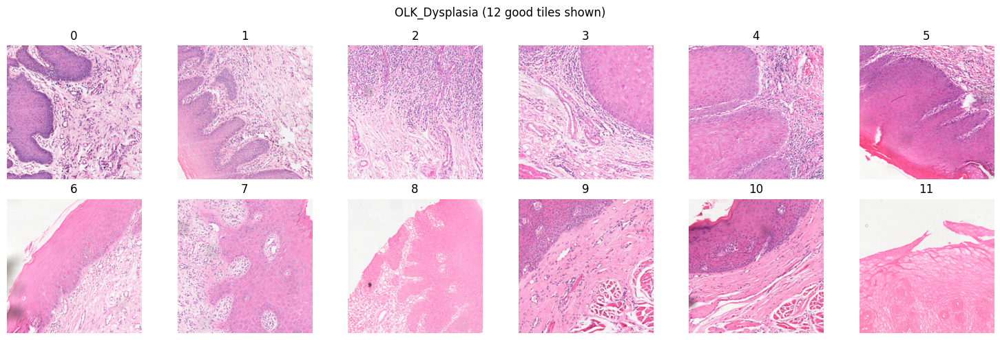

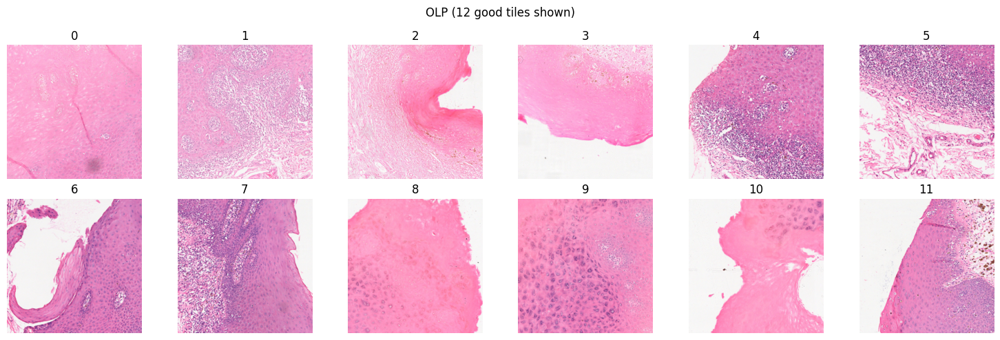

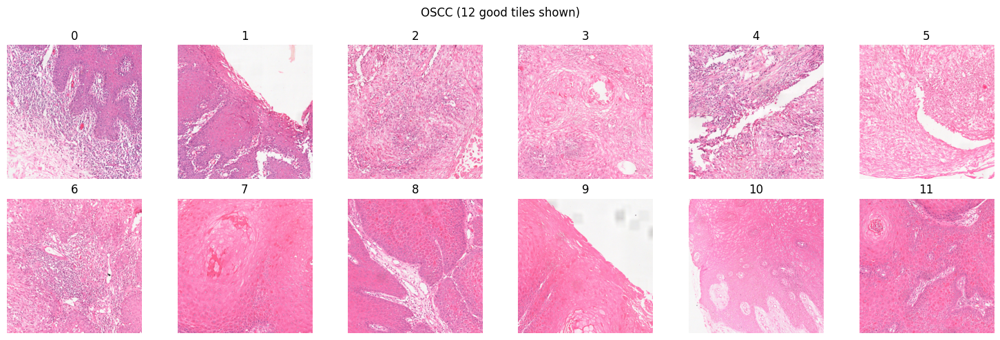

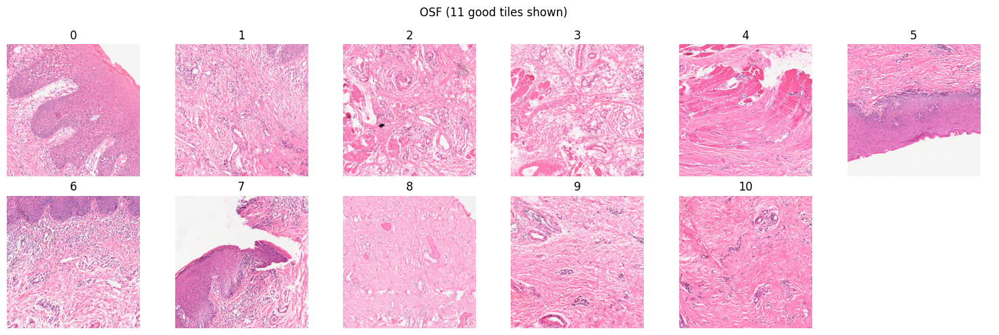

In [ ]:
import cv2
def good_tile(p):
    a = np.array(Image.open(p).convert('RGB').resize((256,256)))
    tissue = (rgb2hsv(a)[...,1] > 0.15).mean()                   # how much tissue
    sharp = cv2.Laplacian(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()  # blur check
    return tissue, sharp

cands = {}
for g in groups:
    ts = []
    for k in [k for k in slides if k[0]==g]:                      # all slides of the group
        t = sorted(x for x in slides[k] if os.path.basename(x).lower().startswith('tile'))
        ts += t[::max(1, len(t)//15)]                             # ~15 tiles per slide
    ok = []
    for p in ts:
        tis, sh = good_tile(p)
        if tis > 0.6 and sh > 50: ok.append(p)                    # mostly tissue and sharp
        if len(ok) >= 12: break
    cands[g] = ok
    fig, ax = plt.subplots(2, 6, figsize=(15,5))
    for i, a in enumerate(ax.ravel()):
        a.axis('off')
        if i < len(ok):
            a.imshow(Image.open(ok[i]).resize((256,256))); a.set_title(str(i))
    plt.suptitle(f'{g} ({len(ok)} good tiles shown)'); plt.tight_layout(); plt.show()

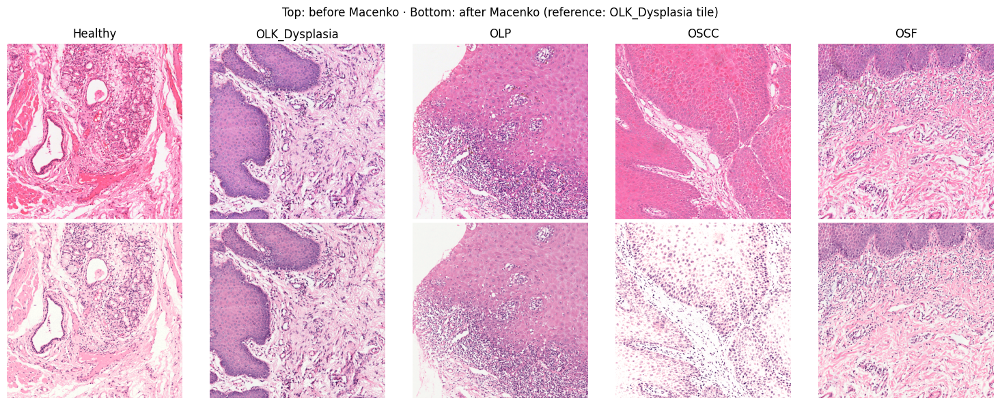

Saved: /content/drive/MyDrive/FYP_G18_pilot/01_tiles/fig3_macenko.png


In [ ]:
# Cell A: Macenko before / after on hand picked tiles (fig3)
CHOICE = {'Healthy': 6, 'OLK_Dysplasia': 0, 'OLP': 4, 'OSCC': 0, 'OSF': 6}

samples = {g: np.array(Image.open(cands[g][CHOICE[g]]).convert('RGB')) for g in groups}
norm = Macenko().fit(samples['OLK_Dysplasia'])        # best stained tile as the reference

fig, ax = plt.subplots(2, len(groups), figsize=(3*len(groups), 6))
for i, g in enumerate(groups):
    t = samples[g]
    try:
        n = norm.transform(t)
    except Exception:
        n = t
    ax[0, i].imshow(t); ax[0, i].set_title(g); ax[0, i].axis('off')
    ax[1, i].imshow(n); ax[1, i].axis('off')
plt.suptitle('Top: before Macenko · Bottom: after Macenko (reference: OLK_Dysplasia tile)')
plt.tight_layout()
plt.savefig(OUT + '/fig3_macenko.png', dpi=200)
plt.show()
print('Saved:', OUT + '/fig3_macenko.png')

53 .svs files found
     group                    file  width  height                  mpp  \
0  Healthy   2026-10-22-1808-2.svs  17088   20192  0.52810000000000001   
1  Healthy   2026-10-22-1810-3.svs  15536   13984  0.52810000000000001   
2  Healthy   2026-10-22-1812-4.svs  17088   20192  0.52810000000000001   
3  Healthy   2026-10-22-1814-5.svs  10880   10880  0.52810000000000001   
4  Healthy   2026-10-22-1817-6.svs  24848   29504  0.52810000000000001   
5  Healthy   2026-10-22-1819-7.svs  18640   17088  0.52810000000000001   
6  Healthy   2026-10-22-1821-8.svs  17088   13984  0.52810000000000001   
7  Healthy  2026-10-28-1403-16.svs  21744   18640  0.52810000000000001   
8  Healthy  2026-10-28-1405-17.svs  20192   20192  0.52810000000000001   
9  Healthy  2026-10-28-1407-18.svs  13984   17088  0.52810000000000001   

  objective  
0        20  
1        20  
2        20  
3        20  
4        20  
5        20  
6        20  
7        20  
8        20  
9        20  

mpp values

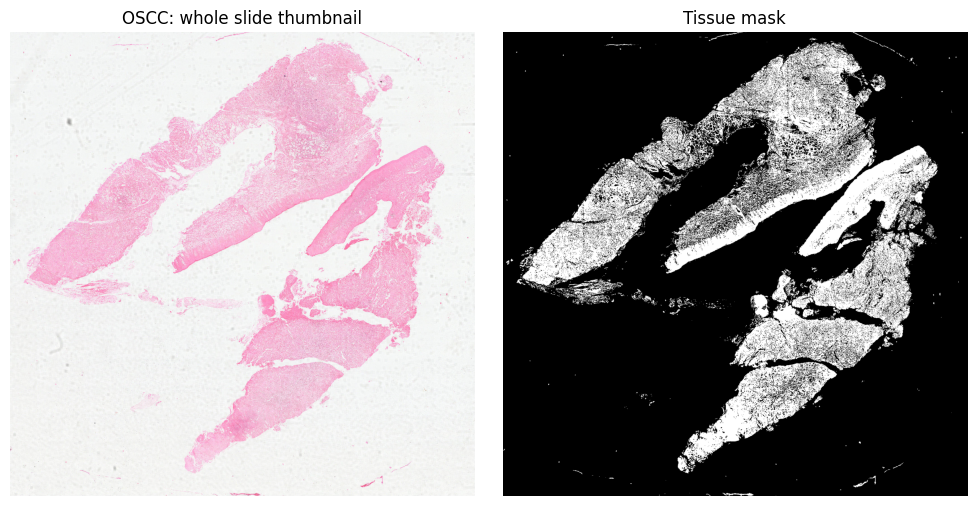

Saved: /content/drive/MyDrive/FYP_G18_pilot/01_tiles/fig1_thumbnail_mask.png


In [ ]:
# Cell B: pixel size from the .svs files and a whole slide thumbnail (fig1)
import openslide

svs = sorted(glob.glob(ROOT + '/**/*.svs', recursive=True))
print(len(svs), '.svs files found')

info = []
for p in svs:
    try:
        s = openslide.OpenSlide(p)
        info.append(dict(group=p.replace(ROOT, '').strip('/').split('/')[0],
                         file=os.path.basename(p),
                         width=s.dimensions[0], height=s.dimensions[1],
                         mpp=s.properties.get('openslide.mpp-x'),
                         objective=s.properties.get('openslide.objective-power')))
    except Exception as e:
        print('could not open', os.path.basename(p), e)

svs_df = pd.DataFrame(info)
svs_df.to_csv(OUT + '/svs_info.csv', index=False)
print(svs_df.head(10))
print('\nmpp values (µm per pixel):', svs_df['mpp'].unique())
print('objective (magnification):', svs_df['objective'].unique())

# Figure 1: one OSCC slide thumbnail and its tissue mask
p = next(x for x in svs if '/OSCC/' in x)
th = np.array(openslide.OpenSlide(p).get_thumbnail((1500, 1500)).convert('RGB'))
tm = rgb2hsv(th)[..., 1] > 0.15                      # same fixed threshold as the tile filter

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(th); ax[0].set_title('OSCC: whole slide thumbnail'); ax[0].axis('off')
ax[1].imshow(tm, cmap='gray'); ax[1].set_title('Tissue mask'); ax[1].axis('off')
plt.tight_layout()
plt.savefig(OUT + '/fig1_thumbnail_mask.png', dpi=200)
plt.show()
print('Saved:', OUT + '/fig1_thumbnail_mask.png')

In [ ]:
# Cell C: how many tiles pass the tissue and sharpness filter (numbers for the slide)
# checks every 3rd tile to keep it fast
rows = []
for (g, s), fs in slides.items():
    tiles = sorted(x for x in fs if os.path.basename(x).lower().startswith('tile'))
    sample = tiles[::3]
    good = 0
    for p in sample:
        tis, sh = good_tile(p)
        if tis > 0.6 and sh > 50:
            good += 1
    rows.append(dict(group=g, slide=s, tiles=len(tiles),
                     est_good_tiles=round(good / max(1, len(sample)) * len(tiles))))

q = pd.DataFrame(rows)
q.to_csv(OUT + '/tile_quality.csv', index=False)

summary = q.groupby('group').agg(slides=('slide', 'count'),
                                 all_tiles=('tiles', 'sum'),
                                 good_tiles=('est_good_tiles', 'sum'))
summary['good_%'] = (100 * summary.good_tiles / summary.all_tiles).round(0)
print(summary)
print('\nTOTAL:', int(summary.all_tiles.sum()), 'tiles,',
      int(summary.good_tiles.sum()), 'good tiles',
      f"({100*summary.good_tiles.sum()/summary.all_tiles.sum():.0f}%)")

In [15]:
q = pd.read_csv(OUT + '/tile_quality.csv')
s = q.groupby('group').agg(slides=('slide','count'),
                           all_tiles=('tiles','sum'),
                           good_tiles=('est_good_tiles','sum'))
s['good_%'] = (100 * s.good_tiles / s.all_tiles).round(1)
print(s)
print('\nTOTAL:', s.all_tiles.sum(), 'tiles,', s.good_tiles.sum(), 'good',
      f"({100*s.good_tiles.sum()/s.all_tiles.sum():.1f}%)")

               slides  all_tiles  good_tiles  good_%
group                                               
Healthy            11       1436         288    20.1
OLK_Dysplasia      10       1685         258    15.3
OLP                17       1446         147    10.2
OSCC                9       2353         555    23.6
OSF                 6        785         147    18.7

TOTAL: 7705 tiles, 1395 good (18.1%)
